In [2]:
import urllib.request, tarfile

url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
urllib.request.urlretrieve(url, "aclImdb_v1.tar.gz")
with tarfile.open("aclImdb_v1.tar.gz") as t:
    t.extractall()

/tmp/ipykernel_2122/3236100977.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall()


In [3]:
import os
import pandas as pd

def load_split(split):
    rows = []
    for label, name in [(1, "pos"), (0, "neg")]:
        folder = f"aclImdb/{split}/{name}"
        for fname in os.listdir(folder):
            with open(os.path.join(folder, fname), encoding="utf-8") as f:
                rows.append({"text": f.read(), "label": label})
    return pd.DataFrame(rows)

train_df = load_split("train")
test_df = load_split("test")

train_df.head()

,text,label
0,If you haven't already seen this movie of Mary...,1
1,"Never realized that Charles Boyer, (Luis Denar...",1
2,Peter Jacksons version(s) are better films ove...,1
3,The plot of the story and the performance of t...,1
4,"Having been a fan of 'Columbo', I was sorely d...",1


In [4]:
import requests

url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

response = requests.get(url)

with open("aclIMDB_v1.tar.gz", "wb") as f:
    f.write(response.content)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [5]:
import tarfile

with tarfile.open("aclIMDB_v1.tar.gz", "r:gz") as tar:
    tar.extractall()

print("Dataset extracted successfully!")

/tmp/ipykernel_2122/1984082216.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Dataset extracted successfully!


In [6]:
import os

print(os.path.exists("aclImdb/train/pos"))
print(len(os.listdir("aclImdb/train/pos")))
print(len(os.listdir("aclImdb/train/neg")))

True
12500
12500


In [7]:
def load_dataset(folder_path):
    reviews = []

    for filename in os.listdir(folder_path):
        if filename.endswith('.txt'):
            file_path = os.path.join(folder_path, filename)

            with open(file_path, 'r', encoding='utf-8') as file:
                reviews.append(file.read())

    return reviews

In [8]:
import os
import urllib.request
import tarfile

# Automatically download and extract if the dataset directory does not exist
if not os.path.exists("aclImdb"):
    print("Dataset not found. Downloading...")
    url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
    tar_path = "aclImdb_v1.tar.gz"
    urllib.request.urlretrieve(url, tar_path)

    print("Extracting dataset...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall()
    print("Dataset successfully downloaded and extracted!")

train_pos_path = "aclImdb/train/pos"
train_neg_path = "aclImdb/train/neg"
test_pos_path = "aclImdb/test/pos"
test_neg_path = "aclImdb/test/neg"

if os.path.exists(train_pos_path):
    train_pos_reviews = load_dataset(train_pos_path)
    train_neg_reviews = load_dataset(train_neg_path)
    test_pos_reviews = load_dataset(test_pos_path)
    test_neg_reviews = load_dataset(test_neg_path)
    print(f"Successfully loaded reviews!")
    print(f"Train positive reviews loaded: {len(train_pos_reviews)}")
else:
    print("Error: Dataset directory could not be prepared.")

Successfully loaded reviews!
Train positive reviews loaded: 12500


In [9]:
import pandas as pd

# Create training DataFrame
train_df = pd.DataFrame({
    'review': train_pos_reviews + train_neg_reviews,
    'label': [1] * len(train_pos_reviews) + [0] * len(train_neg_reviews)
})

# Create testing DataFrame
test_df = pd.DataFrame({
    'review': test_pos_reviews + test_neg_reviews,
    'label': [1] * len(test_pos_reviews) + [0] * len(test_neg_reviews)
})

# Display the first few rows
print("Training DataFrame:")
display(train_df.head())

print("\nTesting DataFrame:")
display(test_df.head())

Training DataFrame:


,review,label
0,If you haven't already seen this movie of Mary...,1
1,"Never realized that Charles Boyer, (Luis Denar...",1
2,Peter Jacksons version(s) are better films ove...,1
3,The plot of the story and the performance of t...,1
4,"Having been a fan of 'Columbo', I was sorely d...",1



Testing DataFrame:


,review,label
0,THIS REVIEW MAY CONTAIN SPOILERS! The Decline ...,1
1,"Seeing this show gives me respect for MTV, tho...",1
2,"After you have seen enough movies, there is ve...",1
3,This is movie is actually one of my all time f...,1
4,Tex Avery's tenure as director of cartoons for...,1


In [10]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (25000, 2)
Testing shape: (25000, 2)


In [11]:
print("===== TRAIN DATASET INFO =====")
train_df.info()

print("\n===== TEST DATASET INFO =====")
test_df.info()

print("\n===== TRAIN DATASET DESCRIPTION =====")
print(train_df.describe())

print("\n===== TEST DATASET DESCRIPTION =====")
print(test_df.describe())

===== TRAIN DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

===== TEST DATASET INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

===== TRAIN DATASET DESCRIPTION =====
             label
count  25000.00000
mean       0.50000
std        0.50001
min        0.00000
25%        0.00000
50%        0.50000
75%        1.00000
max        1.00000

===== TEST DATASET DESCRIPTION =====
             label
count  25000.00000
mean       0.50000
std        0.50001
min   

In [12]:
print("===== TRAIN LABEL DISTRIBUTION =====")
print(train_df["label"].value_counts())

print("\n===== TEST LABEL DISTRIBUTION =====")
print(test_df["label"].value_counts())

===== TRAIN LABEL DISTRIBUTION =====
label
1    12500
0    12500
Name: count, dtype: int64

===== TEST LABEL DISTRIBUTION =====
label
1    12500
0    12500
Name: count, dtype: int64


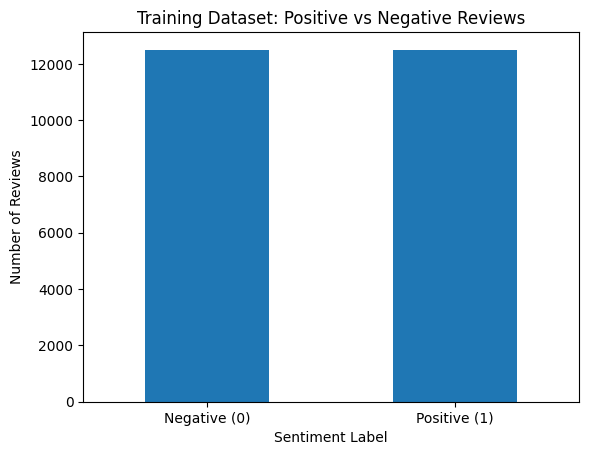

In [13]:
import matplotlib.pyplot as plt

train_df["label"].value_counts().sort_index().plot(kind="bar")

plt.title("Training Dataset: Positive vs Negative Reviews")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"], rotation=0)
plt.show()

In [14]:
train_df["review_length"] = train_df["review"].str.len()
test_df["review_length"] = test_df["review"].str.len()

print("===== REVIEW LENGTH STATISTICS =====")
print(train_df["review_length"].describe())

===== REVIEW LENGTH STATISTICS =====
count    25000.00000
mean      1325.06964
std       1003.13367
min         52.00000
25%        702.00000
50%        979.00000
75%       1614.00000
max      13704.00000
Name: review_length, dtype: float64


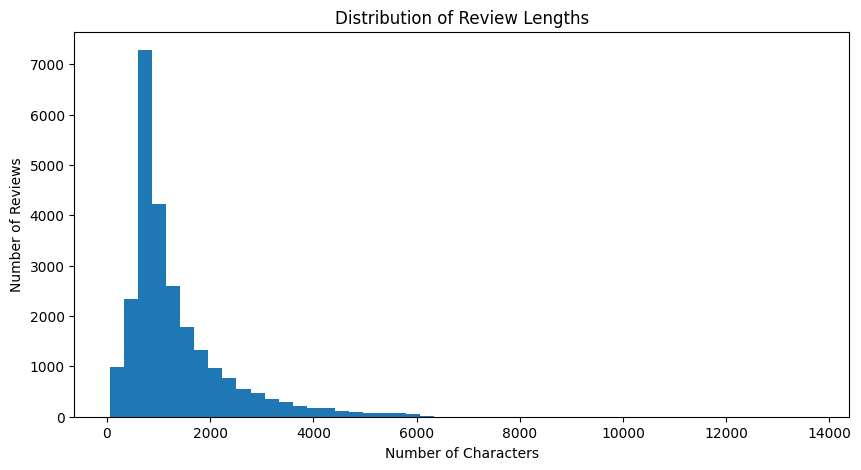

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(train_df["review_length"], bins=50)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")
plt.show()

In [16]:
print("===== POSITIVE REVIEW SAMPLES =====")

for review in train_df[train_df["label"] == 1]["review"].sample(3, random_state=42):
    print("\n", review[:1000])

===== POSITIVE REVIEW SAMPLES =====

 This horror movie, based on the novel of the same name, suffers from flawed production and choppy, amateurish direction, but it's nonetheless strangely compelling. Unlike shocker horror flicks such as The Exorcist, this movie takes the viewer on a slow yet relentless dip into a pool of evil. It drifts into horror, which dawns on the audience with the same dreamlike slowness as it dawns on the poor girl who's been unwittingly chosen to be the next sentinel. Her appointed task is to sit at the gates of hell and prevent evil from erupting into the world. This falls on her in atonement for her attempted suicide earlier in her life.<br /><br />The story is true to the book, which was riveting, but the way it's edited can lose the viewer. There are subtleties in the plot that are shaved away and never explained satisfactorily, which hurts this film. That's a pity. The Sentinel is not an edge-of-your-seat kind of flick; it's more a watch-and-squirm uncomf

In [17]:
print("===== NEGATIVE REVIEW SAMPLES =====")

for review in train_df[train_df["label"] == 0]["review"].sample(3, random_state=42):
    print("\n", review[:1000])

===== NEGATIVE REVIEW SAMPLES =====

 I was very excited about this film when I first saw the previews. Normally I see a preview this good and I buy the film outright. Something told me to... you know watch it first. I'm glad I did. Keira Knightley ruined all future films for me with this role. In the 2nd Pirates movie when it came out I went to see it. All I saw was Domino Harvey and I hated her more for it. I think that had to do with her hair and having to cut it short for Domino.<br /><br />Domino who? Who is Domino Harvey? I still don't really know or care. I don't know who she was in real life or who she was in this film. I didn't care about her character and even Keira getting partically naked didn't make it worth the movie. The direction was definitely lacking. The writing was trite and shallow. The editing was horrible. I don't mind the style so much as the poor overuse of it. There's a place for it. Good examples of choppy, MTV style, colorful editing (not sure if there's an 

In [18]:
# Shuffle the training dataset
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Split into training and validation sets
train_size = int(0.9 * len(shuffled_df))

train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))

Training samples: 22500
Validation samples: 2500


In [19]:
print("Training label distribution:")
print(train_data["label"].value_counts())

print("\nValidation label distribution:")
print(val_data["label"].value_counts())

Training label distribution:
label
1    11253
0    11247
Name: count, dtype: int64

Validation label distribution:
label
0    1253
1    1247
Name: count, dtype: int64


In [20]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [21]:
sample_texts = train_data["review"].sample(3, random_state=42).tolist()

tokenized_samples = tokenizer(
    sample_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

print("Input IDs shape:", tokenized_samples["input_ids"].shape)
print("Attention mask shape:", tokenized_samples["attention_mask"].shape)

Input IDs shape: torch.Size([3, 128])
Attention mask shape: torch.Size([3, 128])


In [22]:
tokens = tokenizer.tokenize(sample_texts[0])

print("Original review:")
print(sample_texts[0][:500])

print("\nFirst 50 tokens:")
print(tokens[:50])

Original review:
I've read the other reviews and found some to be comparison of movie v real life (eg what it takes to get into music school), Britney Bashing, etc, etc. so let's focus on the movie and the message.<br /><br />I have rated this movie 7 out of 10 for the age range 8 to 14 years, and for a family movie. For the average adult male.... 2 out of 10.<br /><br />I like pop/rock music, i'm 45. I know of Britney Spears but never realised she actually sang Stronger until i read the credits and these review

First 50 tokens:
['i', "'", 've', 'read', 'the', 'other', 'reviews', 'and', 'found', 'some', 'to', 'be', 'comparison', 'of', 'movie', 'v', 'real', 'life', '(', 'e', '##g', 'what', 'it', 'takes', 'to', 'get', 'into', 'music', 'school', ')', ',', 'britney', 'bash', '##ing', ',', 'etc', ',', 'etc', '.', 'so', 'let', "'", 's', 'focus', 'on', 'the', 'movie', 'and', 'the', 'message']


In [23]:
print("First 50 token IDs:")
print(tokenized_samples["input_ids"][0][:50])

First 50 token IDs:
tensor([  101,  1045,  1005,  2310,  3191,  1996,  2060,  4391,  1998,  2179,
         2070,  2000,  2022,  7831,  1997,  3185,  1058,  2613,  2166,  1006,
         1041,  2290,  2054,  2009,  3138,  2000,  2131,  2046,  2189,  2082,
         1007,  1010, 29168, 24234,  2075,  1010,  4385,  1010,  4385,  1012,
         2061,  2292,  1005,  1055,  3579,  2006,  1996,  3185,  1998,  1996])


In [24]:
MAX_LENGTH = 128

In [25]:
max_length=128

In [26]:
import torch
from torch.utils.data import Dataset

MAX_LENGTH = 128

class IMDBDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data = data
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        review = self.data.iloc[idx]["review"]
        label = self.data.iloc[idx]["label"]

        encoding = self.tokenizer(
            review,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        return input_ids, int(label)

In [27]:
# Instantiate the datasets using our custom IMDBDataset class
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)

# Retrieve and inspect the first sample
input_ids, label = train_dataset[0]
print("Input IDs shape:", input_ids.shape)
print("Label:", label)

Input IDs shape: torch.Size([128])
Label: 1


In [28]:
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

Train dataset size: 22500
Validation dataset size: 2500
Test dataset size: 25000


In [29]:
input_ids, label = train_dataset[0]

print("Input IDs shape:", input_ids.shape)
print("Label:", label)

Input IDs shape: torch.Size([128])
Label: 1


In [30]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [31]:
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Number of training batches: 704
Number of validation batches: 79
Number of test batches: 782


In [32]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,                          # 4 heads * 32 = 128
    "dropout_rate": 0.1,
    "use_bias": True
}

In [33]:
import torch
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.Q_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.K_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.V_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(
            torch.ones(
                config["context_size"],
                config["context_size"]
            )
        )

        self.register_buffer(
            "casual_attention_mask",
            casual_attention_mask
        )

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape

        Q = self.Q_weights(input)
        K = self.K_weights(input)
        V = self.V_weights(input)

        # Q @ K^T
        attention_scores = Q @ K.transpose(1, 2)

        # Causal Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float("-inf")
        )

        # Scale attention scores
        attention_scores = attention_scores / math.sqrt(K.shape[-1])

        # Convert scores to probabilities
        attention_scores = torch.softmax(attention_scores, dim=-1)

        # Apply dropout
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

In [34]:
# Define device to resolve the NameError
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

attention_head = AttentionHead(config).to(device)

dummy_input = torch.randn(
    BATCH_SIZE,
    config["context_size"],
    config["d_embed"]
).to(device)

attention_output = attention_head(dummy_input)

print("AttentionHead output shape:", attention_output.shape)

Using device: cpu
AttentionHead output shape: torch.Size([32, 128, 32])


In [35]:
attention_head = AttentionHead(config).to(device)

dummy_input = torch.randn(
    BATCH_SIZE,
    config["context_size"],
    config["d_embed"]
).to(device)

attention_output = attention_head(dummy_input)

print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


In [36]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        # Token embedding layer
        self.token_embedding_layer = nn.Embedding(
            config["vocabulary_size"],
            config["d_embed"]
        )

        # Positional embedding layer
        self.positional_embedding_layer = nn.Embedding(
            config["context_size"],
            config["d_embed"]
        )

        # Transformer layers
        blocks = [
            Block(config)
            for _ in range(config["layers_num"])
        ]
        self.layers = nn.Sequential(*blocks)

        # Final layer normalization
        self.layer_norm = nn.LayerNorm(config["d_embed"])

        # Classification output layer
        self.classification_head = nn.Linear(
            config["d_embed"],
            config["num_classes"],
            bias=False
        )

    def forward(self, token_ids):
        batch_size, tokens_num = token_ids.shape

        # Step 1: Token and positional embeddings
        x = self.token_embedding_layer(token_ids)

        positions = torch.arange(
            tokens_num,
            device=token_ids.device
        )

        pos_embed = self.positional_embedding_layer(positions)

        x = x + pos_embed.unsqueeze(0)

        # Step 2: Transformer layers
        x = self.layers(x)
        x = self.layer_norm(x)

        # Step 3: Mean pooling across the sequence dimension
        x = torch.mean(x, dim=1)

        # Step 4: Generate classification logits
        logits = self.classification_head(x)

        return logits

In [37]:
import torch
import torch.nn as nn

# 1. MultiHeadAttention implementation
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.heads = nn.ModuleList([
            AttentionHead(config) for _ in range(config["heads_num"])
        ])
        # Project concatenated outputs of heads back to d_embed
        self.out_projection = nn.Linear(
            config["heads_num"] * config["head_size"],
            config["d_embed"],
            bias=config["use_bias"]
        )
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, x):
        # Concatenate outputs from all attention heads along the feature dimension
        head_outputs = torch.cat([head(x) for head in self.heads], dim=-1)
        out = self.out_projection(head_outputs)
        return self.dropout(out)

# 2. FeedForward Network implementation
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"], bias=config["use_bias"]),
            nn.ReLU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"], bias=config["use_bias"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, x):
        return self.net(x)

# 3. Block implementation combining Attention, MLP, and Residuals
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.layer_norm1 = nn.LayerNorm(config["d_embed"])
        self.attention = MultiHeadAttention(config)
        self.layer_norm2 = nn.LayerNorm(config["d_embed"])
        self.feed_forward = FeedForward(config)

    def forward(self, x):
        # Pre-LN structure with residual connections
        x = x + self.attention(self.layer_norm1(x))
        x = x + self.feed_forward(self.layer_norm2(x))
        return x

# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Create a dummy batch
dummy_token_ids = torch.randint(
    0,
    config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[0.1367, 0.1101],
        [0.0349, 0.0625]], grad_fn=<SliceBackward0>)


In [38]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size matches the input
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

print("All DemoGPT assertions passed!")

All DemoGPT assertions passed!


In [39]:
def calculate_accuracy(model, data_loader, device):
    model.eval()

    correct_predictions = 0
    total_predictions = 0

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)

            predictions = torch.argmax(logits, dim=1)

            correct_predictions += (predictions == labels).sum().item()
            total_predictions += labels.size(0)

    accuracy = (correct_predictions / total_predictions) * 100

    return accuracy

In [40]:
val_accuracy = calculate_accuracy(
    demo_gpt,
    val_loader,
    device
)

print(f"Initial validation accuracy: {val_accuracy:.2f}%")

Initial validation accuracy: 51.04%


In [42]:
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 3

# Initialize model, loss, and optimizer
model = DemoGPT(config).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=3e-4
)

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):

        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # Forward pass
        logits = model(input_ids)

        # Calculate loss
        loss = criterion(logits, labels)

        # Set gradients to zero
        optimizer.zero_grad()

        # Backward pass
        loss.backward()

        # Step the optimizer
        optimizer.step()

        running_loss += loss.item()

        # Log training progress
        if (step + 1) % 100 == 0:
            print(
                f"Epoch [{epoch+1}/{EPOCHS}], "
                f"Step [{step+1}/{len(train_loader)}], "
                f"Loss: {running_loss/100:.4f}"
            )
            running_loss = 0.0

    # Evaluate validation accuracy
    val_accuracy = calculate_accuracy(
        model,
        val_loader,
        device
    )

    print(
        f"Epoch {epoch+1} - "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/3], Step [100/704], Loss: 0.6992
Epoch [1/3], Step [200/704], Loss: 0.6815
Epoch [1/3], Step [300/704], Loss: 0.6572
Epoch [1/3], Step [400/704], Loss: 0.6470
Epoch [1/3], Step [500/704], Loss: 0.6229
Epoch [1/3], Step [600/704], Loss: 0.5844
Epoch [1/3], Step [700/704], Loss: 0.5611
Epoch 1 - Validation Accuracy: 69.88%
Epoch [2/3], Step [100/704], Loss: 0.5195
Epoch [2/3], Step [200/704], Loss: 0.5374
Epoch [2/3], Step [300/704], Loss: 0.4944
Epoch [2/3], Step [400/704], Loss: 0.4976
Epoch [2/3], Step [500/704], Loss: 0.4952
Epoch [2/3], Step [600/704], Loss: 0.4877
Epoch [2/3], Step [700/704], Loss: 0.4793
Epoch 2 - Validation Accuracy: 75.72%
Epoch [3/3], Step [100/704], Loss: 0.4428
Epoch [3/3], Step [200/704], Loss: 0.4289
Epoch [3/3], Step [300/704], Loss: 0.4338
Epoch [3/3], Step [400/704], Loss: 0.4445
Epoch [3/3], Step [500/704], Loss: 0.4236
Epoch [3/3], Step [600/704], Loss: 0.4244
Epoch [3/3], Step [700/704], Loss: 0.4175
Epoch 3 - Validation Accuracy: 77.92%


In [ ]:
print("Using device:", device)

In [43]:
test_accuracy = calculate_accuracy(
    model,
    test_loader,
    device
)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 76.54%
